# Mapas de Tamburco para Ampay Vivo

Genera capas espectrales, de relieve y de clima para el área de estudio con **GeoPandas y Rasterio**. El ejemplo se puede ejecutar con los archivos incluidos. Si activas las descargas, el cuaderno utiliza tu sesión de Earth Engine, aplica los filtros de cobertura y guarda los insumos por separado.

El límite incluido es el shapefile **tamburco_glaciar** del equipo, cuyo atributo territorial corresponde al distrito de Tamburco. La extensión oficial del Santuario Nacional de Ampay es de **3 635,50 ha** según [SERNANP](https://www.gob.pe/institucion/sernanp/informes-publicaciones/1928581-santuario-nacional-de-ampay). Selecciona el polígono oficial en la configuración para reportar resultados de esa área protegida.

## Mapas recomendados

| Tema | Capas | Lectura principal |
|---|---|---|
| Imágenes | Color natural, falso color infrarrojo y falso color SWIR | Identificar la cobertura visible y revisar los resultados cerca de lagunas y del nevado. |
| Vegetación | NDVI, SAVI, EVI, NDMI y NDRE | Comparar vigor, sensibilidad al suelo, respuesta del dosel, humedad espectral y borde rojo. |
| Agua y criósfera | NDWI, MNDWI, NDSI, frecuencias, polígonos candidatos y ocurrencia histórica JRC | Ubicar agua superficial y sectores con nieve/hielo. Contrastar los resultados con color natural, SCL y relieve. |
| Cambios y calidad | ΔNDVI, ΔNDMI y días válidos por píxel | Comparar el mismo mes de dos años y distinguir los vacíos debidos a cobertura insuficiente. |
| Relieve | Elevación, pendiente, orientación y sombreado | Entender la topografía de cabecera y su influencia en la cobertura y la observación satelital. |
| Lluvia | CHIRPS mensual, anual y anomalía; NASA IMERG mensual | Mostrar el contexto de lluvias y comparar dos productos de forma independiente. |
| Temperatura y energía | MODIS LST de día y de noche; ERA5-Land T2M, anomalía de T2M y radiación | Contrastar temperatura de superficie, temperatura del aire y energía solar en sus grillas de origen. |

Para la primera vista del geoportal, destaca color natural, NDVI, NDMI, ocurrencia histórica de agua, NDSI, pendiente y lluvia mensual. Conserva **Días válidos por píxel** junto con las capas espectrales. Las cuadrículas climáticas se muestran en un contexto regional del distrito.

In [1]:
# Si falta una dependencia, puedes ejecutar: %pip install -r requirements.txt

from datetime import date
from pathlib import Path
import shutil

import pandas as pd
from IPython.display import Image, display

from ampay_mapas import (
    Catalogo, cargar_area, mapas_espectrales, mapas_relieve, mapa_agua_historica, mapas_clima, lamina,
)

RAIZ = Path.cwd()
INSUMOS = RAIZ / "insumos"
LIMITE = INSUMOS / "tamburco_glaciar.geojson"
NOMBRE_AREA = "Distrito de Tamburco"
PROYECTO_GEE = "wise-brook-514714-p4"
ASSET_GEE = "projects/wise-brook-514714-p4/assets/tamburco_glaciar"

PERIODO_S2 = "2026-08"
REFERENCIA_S2 = "2020-08"  # Usa None para omitir los mapas de cambio.
MES_CLIMA = "2026-08"
ANIO_LLUVIA_ANUAL = None   # Ejemplo: 2025, con un año completo en CHIRPS.
REFERENCIA_CLIMA = (1991, 2020)

DESCARGAR_S2_GEE = False
DESCARGAR_CLIMA_GEE = False
LEER_LIMITE_GEE = False

MIN_DIAS_VALIDOS = 2
MIN_POLIGONO_HA = 0.12
MARGEN_CLIMA_KM = 55

for mes in (PERIODO_S2, REFERENCIA_S2, MES_CLIMA):
    if mes is not None:
        date.fromisoformat(mes + "-01")
etiqueta_salida = PERIODO_S2 if PERIODO_S2 == MES_CLIMA else f"{PERIODO_S2}_clima_{MES_CLIMA}"
SALIDA = RAIZ / "salidas" / etiqueta_salida
if not INSUMOS.is_dir():
    raise FileNotFoundError("Abre el cuaderno desde la carpeta extraída Mapas_Ampay_Jupyter.")

## Área de estudio y fuentes

GeoPandas verifica que el vector tenga CRS y polígonos válidos. La geometría se lleva a **WGS 84 / UTM 18S (EPSG:32718)** para calcular superficies y aplicar recortes métricos. Si eliges leer el asset, comprueba el nombre y el área resultante antes de publicar.

Las descargas opcionales guardan sus propios archivos. Earth Engine genera los compuestos y subconjuntos. Rasterio lee las bandas, aplica las fórmulas, conserva NoData y produce los GeoTIFF y las imágenes para el mapa web.

In [2]:
cache = RAIZ / "cache_gee"
if DESCARGAR_S2_GEE or DESCARGAR_CLIMA_GEE or LEER_LIMITE_GEE:
    import ampay_gee as gee
    gee.iniciar(PROYECTO_GEE)
    if LEER_LIMITE_GEE:
        cache.mkdir(exist_ok=True)
        LIMITE = cache / "limite_gee.geojson"
        gee.area_del_asset(ASSET_GEE).to_file(LIMITE, driver="GeoJSON")

area = cargar_area(LIMITE)
area_ha = area.geometry.area.iloc[0] / 10000
print(f"{NOMBRE_AREA}: {area_ha:,.3f} ha · {area.crs}")
catalogo = Catalogo(SALIDA, area, NOMBRE_AREA)

ruta_s2 = (cache if DESCARGAR_S2_GEE else INSUMOS) / "s2"
ruta_clima = (cache if DESCARGAR_CLIMA_GEE else INSUMOS) / "clima" / MES_CLIMA
if DESCARGAR_S2_GEE:
    for mes in dict.fromkeys([PERIODO_S2, REFERENCIA_S2]):
        if mes is not None:
            gee.s2_compuesto(ruta_s2 / mes, area, mes)
if DESCARGAR_CLIMA_GEE:
    gee.cargar_clima(ruta_clima, area, MES_CLIMA, margen_km=MARGEN_CLIMA_KM,
                   anio_anual=ANIO_LLUVIA_ANUAL, periodo_referencia=REFERENCIA_CLIMA)

Distrito de Tamburco: 6,931.977 ha · EPSG:32718


## Sentinel-2, agua y nieve

Las bandas incluidas ya están convertidas a **reflectancia** con la escala de cada escena. En los COG de Earth Search se aplica el offset solamente si la escena todavía lo requiere. El ejemplo usa tres días seleccionados de cada agosto. Cada índice se calcula sobre el compuesto de mediana de reflectancia; la frecuencia de detecciones sí se calcula a partir de las observaciones por día.

| Índice | Bandas o fórmula |
|---|---|
| NDVI, SAVI y EVI | B8, B4 y B2 para EVI. SAVI usa L = 0.5. |
| NDMI | (B8 − B11) / (B8 + B11), con B8 agregada a la cuadrícula de 20 m. |
| NDRE | (B8A − B5) / (B8A + B5). |
| NDWI | (B3 − B8) / (B3 + B8). |
| MNDWI y NDSI | Comparten (B3 − B11) / (B3 + B11). Se interpretan con evidencia de cobertura: SCL y máscaras de agua o nieve. |

Agua candidata exige SCL 6 más NDWI y MNDWI positivos. Nieve/hielo candidatos exigen SCL 11, NDSI ≥ 0.40 y reflectancia verde ≥ 0.12. Estos umbrales reproducibles sirven para detección preliminar. Los vectores exigen al menos dos detecciones y frecuencia ≥ 50 %. Usa la ocurrencia histórica de EC JRC/Google para ubicar las lagunas como referencia al revisar la imagen reciente. Los cambios se calculan con píxeles comparables y al menos dos días válidos en ambos períodos.

In [3]:
optico = ruta_s2 / PERIODO_S2
comparacion = ruta_s2 / REFERENCIA_S2 if REFERENCIA_S2 else None
if (optico / "fuente.json").is_file():
    mapas_espectrales(catalogo, optico, comparacion,
                     min_dias=MIN_DIAS_VALIDOS, minimo_ha=MIN_POLIGONO_HA)
else:
    print("Faltan los compuestos del período óptico. Selecciona uno incluido o habilita la descarga GEE.")

Sentinel-2 · 2026-08: 3 días considerados en el compuesto.
Agua candidata: sin polígonos con los criterios seleccionados.


## Relieve y clima

El relieve se deriva del DEM GLO-30 a una cuadrícula métrica de 30 m. La pendiente, orientación y sombreado se calculan con margen alrededor del distrito antes de aplicar el recorte.

- **CHIRPS** ofrece lluvia en celdas de 0.05° e **IMERG** en celdas de 0.1°. Una ventaja de mostrar el contexto regional es que se distinguen esas celdas.
- **MODIS LST** mide temperatura de superficie a aproximadamente 1 km. Se conservan los compuestos con calidad suficiente y se usa su fecha de inicio para asignarlos al mes.
- **ERA5-Land** ofrece T2M en °C y radiación mensual en kWh/m². Las anomalías se calculan con el mismo mes calendario de la referencia.
- En el modo de ejemplo viene **CHIRPS agosto de 2026**. Para obtener otras capas climáticas activa la descarga GEE según la disponibilidad de los productos.


In [4]:
mapas_relieve(catalogo, INSUMOS / "dem_copernicus_glo30.tif")
mapa_agua_historica(catalogo, INSUMOS / "agua_jrc_1984_2024.tif")
mapas_clima(catalogo, ruta_clima, MES_CLIMA)

pisco = pd.read_excel(INSUMOS / "pp_pisco_Nevado.xlsx", usecols=["date", "Enev_ampay_pp"])
pisco["date"] = pd.to_datetime(pisco["date"])
print(f"PISCOp del equipo · {len(pisco)} meses en una serie de referencia, {pisco['date'].min():%Y-%m} a {pisco['date'].max():%Y-%m}.")
display(pisco.loc[pisco["date"].dt.year.between(2016, 2025)].tail(3))

PISCOp del equipo · 540 meses en una serie de referencia, 1981-01 a 2025-12.


,date,Enev_ampay_pp
537,2025-10-01,168.260483
538,2025-11-01,370.509277
539,2025-12-01,179.385300


## Exportación y vista previa

El **GeoTIFF** conserva valores y georreferenciación. Las imágenes **PNG** son transparentes donde falta información y están listas para Leaflet, con metadatos y límites incorporados. Los candidatos vectoriales se guardan en **GeoJSON**. Abre **geoportal/vista_previa.html** para recorrer las capas. Consulta **LEEME.md** para instalarlas en el Mapa SIG Interactivo de la v3.

Resultados en salidas/2026-08


,nombre,grupo,periodo,resolucion,cobertura_pct,n_poligonos
0,Color natural,Imágenes Sentinel-2,2026-08,10 m,96.479,NaN
1,Falso color infrarrojo,Imágenes Sentinel-2,2026-08,10 m,96.479,NaN
2,Falso color SWIR,Imágenes Sentinel-2,2026-08,20 m,96.479,NaN
3,NDVI · vigor de la vegetación,Vegetación,2026-08,10 m,96.479,NaN
4,SAVI · vegetación con ajuste al suelo,Vegetación,2026-08,10 m,96.479,NaN
5,EVI · índice mejorado de vegetación,Vegetación,2026-08,10 m,96.040,NaN
6,NDMI · humedad de la vegetación,Vegetación,2026-08,20 m,96.479,NaN
7,NDRE · respuesta del borde rojo,Vegetación,2026-08,20 m,96.479,NaN
8,NDWI · contraste de agua y tierra,Agua y criósfera,2026-08,10 m,96.479,NaN
9,MNDWI · agua superficial,Agua y criósfera,2026-08,20 m,95.618,NaN


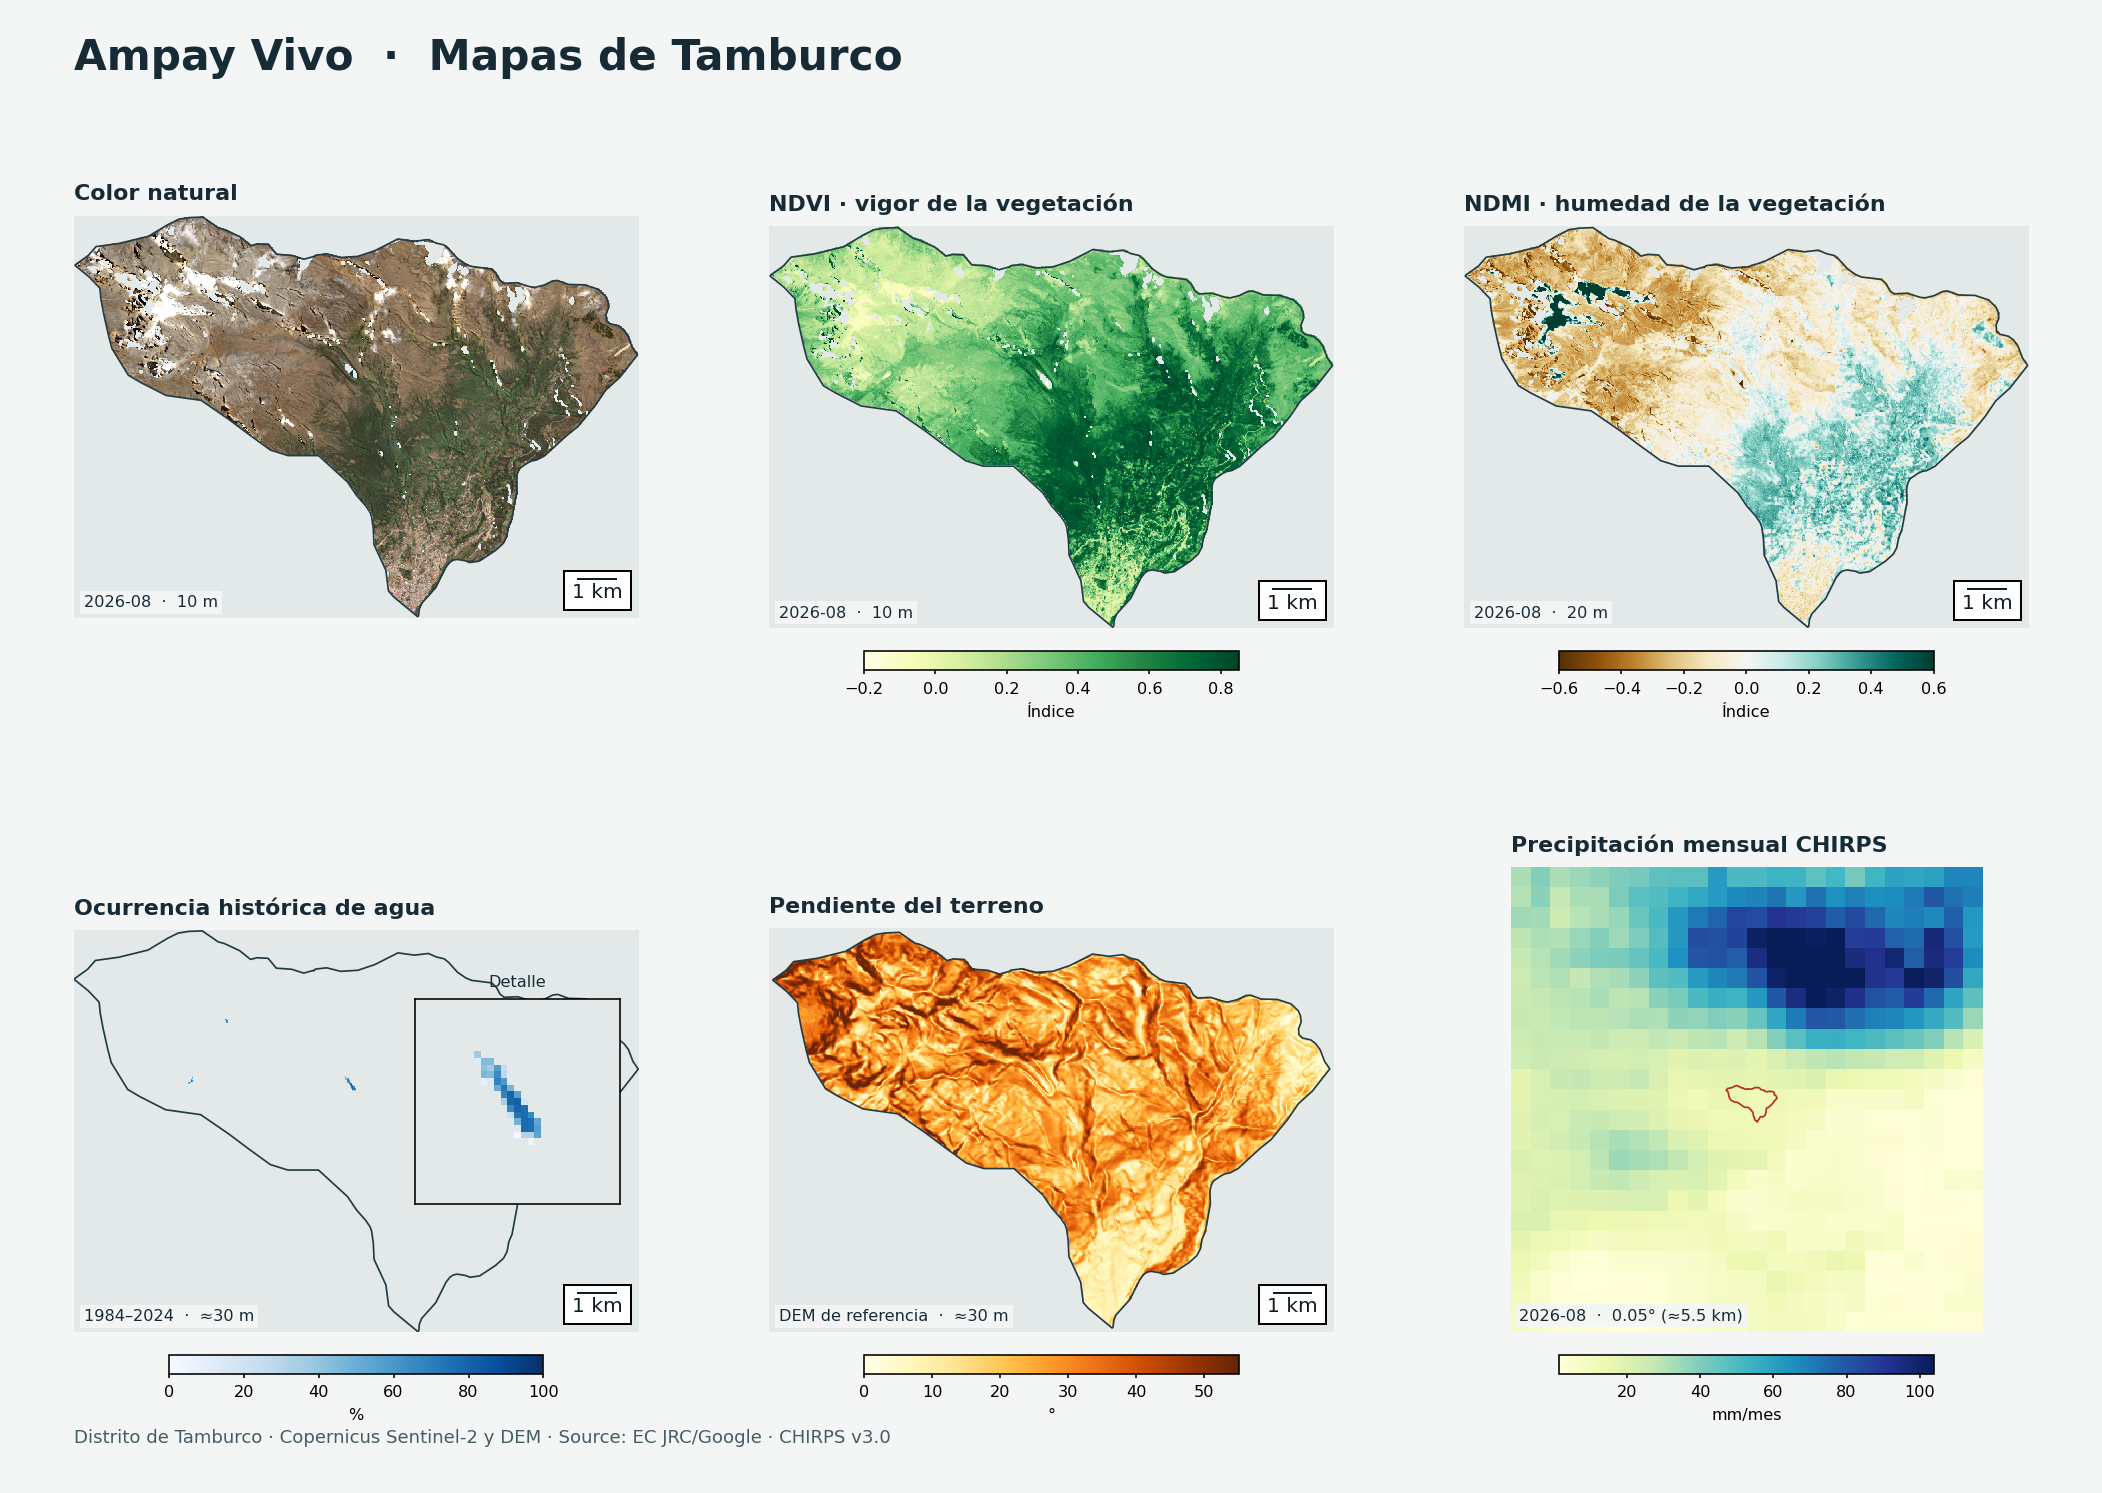

In [5]:
catalogo.escribir()
shutil.copyfile(RAIZ / "vista_previa_plantilla.html", catalogo.web / "vista_previa.html")
lamina(catalogo, ["rgb", "ndvi", "ndmi", "agua_historica", "pendiente", "pp_chirps_mes"],
       SALIDA / "lamina_ampay.png")

tabla = pd.DataFrame(catalogo.capas)
display(tabla.reindex(columns=["nombre","grupo","periodo","resolucion","cobertura_pct","n_poligonos"]))
print(f"Resultados en {SALIDA.relative_to(RAIZ)}")
if (SALIDA / "lamina_ampay.png").is_file():
    display(Image(filename=str(SALIDA / "lamina_ampay.png"), width=1000))

### Fuentes

[Copernicus Sentinel-2 SR y SCL](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED) · [Metadatos del offset en Earth Search](https://github.com/Element84/earth-search/issues/23) · [Copernicus DEM GLO-30](https://registry.opendata.aws/copernicus-dem/) · [EC JRC/Google Global Surface Water v1.5](https://global-surface-water.appspot.com/download) · [CHIRPS v3](https://www.chc.ucsb.edu/data/chirps3) · [NASA GPM IMERG](https://developers.google.com/earth-engine/datasets/catalog/NASA_GPM_L3_IMERG_V07) · [NASA MODIS MOD11A2](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD11A2) · [ERA5-Land mensual](https://developers.google.com/earth-engine/datasets/catalog/ECMWF_ERA5_LAND_MONTHLY_AGGR)